<a href="https://colab.research.google.com/github/PPGCA-MLG/2026S2/blob/main/Aula_08/2RCNN_Deteccao_Objetos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Detecção de Objetos com R-CNN (*Region-based Convolutional Neural Network*)

Este notebook implementa o pipeline completo da arquitetura **R-CNN** (Girshick et al., 2014) para detecção e localização de múltiplos objetos em imagens.

## Pipeline Completo da R-CNN (6 Etapas):
1. **Propostas de Região (*Region Proposals*):** Uso do algoritmo **Selective Search** (`cv2.ximgproc.segmentation.createSelectiveSearchSegmentation`) para gerar cerca de **2.000 regiões candidatas** (*bounding boxes*) com alta probabilidade de conter objetos.
2. **Rotulagem via IoU (*Intersection over Union*):** Comparação de cada proposta com as caixas reais (*Ground Truth*). Regiões com $\text{IoU}\ge 0.7$ são rotuladas como classe positiva (objeto) e regiões com $\text{IoU}\le 0.3$ como **Fundo** (*background*).
3. **Redimensionamento (*Warping*):** Como CNNs padrão exigem entrada espacial fixa, cada recorte proposto de tamanho arbitrário é redimensionado para **`224 × 224`** pixels (na VGG16) ou **`227 × 227`** pixels (na AlexNet).
4. **Extração de Características e Classificação (Transfer Learning):** Passagem de cada recorte pela **VGG16** pré-treinada na ImageNet com ajuste fino (*Fine-Tuning*) e amostragem balanceada para prever $N+1$ classes ($N$ classes de objetos + **Fundo**).
5. **Regressão da Caixa Delimitadora (*Bounding-Box Regression*):** Refinamento das coordenadas da caixa proposta $P = (P_x, P_y, P_w, P_h)$ rumo ao *ground truth* $G$ por meio de um regressor linear Ridge (L2) treinado sobre os mapas de características (`pool5`) para prever os deslocamentos normalizados $(t_x, t_y, t_w, t_h)$.
6. **Pós-processamento — *Non-Maximum Suppression* (NMS):** Eliminação de detecções redundantes sobrepostas por classe sempre que $\text{IoU}(M, B_i) > \tau$ (`tf.image.non_max_suppression`), seguida da avaliação final por **Precisão, Revocação e mAP**.

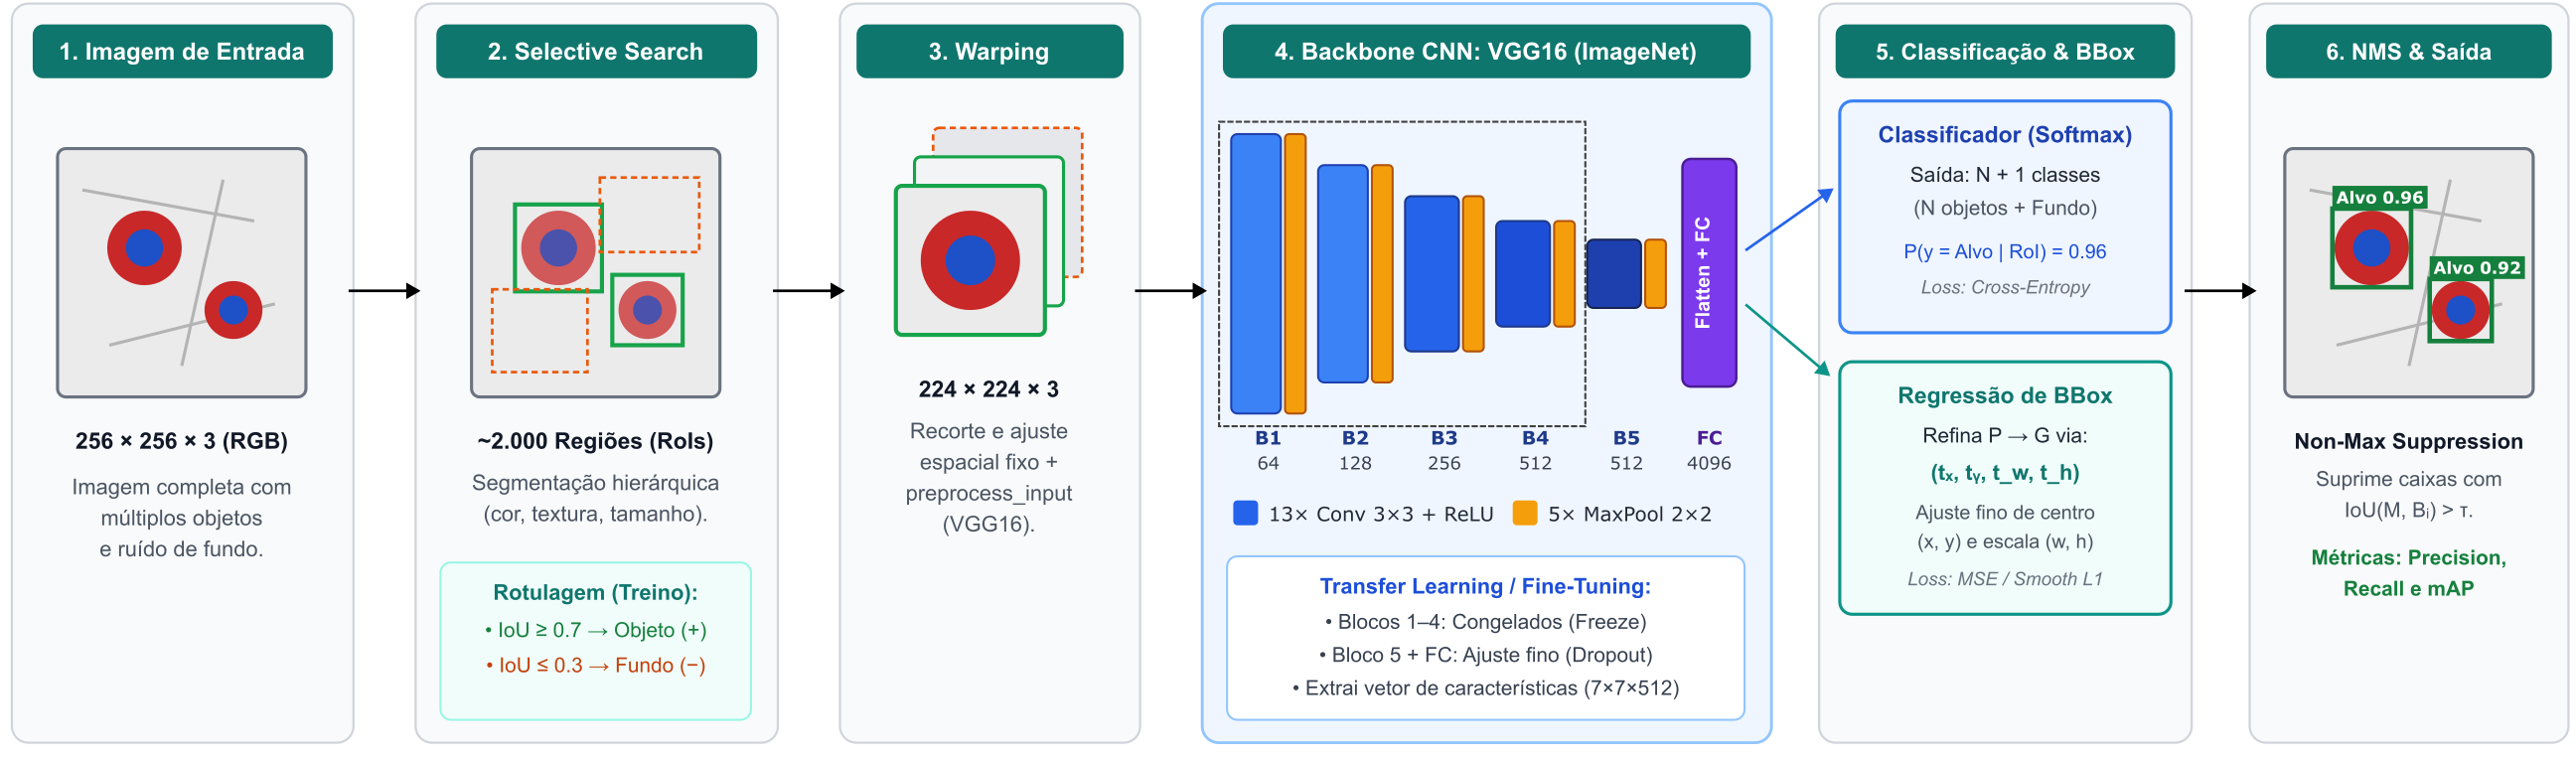


## OpenCV

[OpenCV](https://opencv.org/), criada originalmente pela Intel, é uma das principais bibliotecas de Visão Computacional. Neste notebook usamos o módulo `cv2.ximgproc` para gerar **regiões candidatas (*region proposals*)** com o algoritmo **Selective Search** antes de enviar os recortes à rede neural.

> **Por que usar `opencv-contrib-python-headless`?** O *Selective Search* fica nos módulos adicionais (`contrib`), e a versão `headless` evita dependências de interface gráfica no Google Colab.

In [1]:
# Instalar/garantir opencv-contrib para acesso ao Selective Search (ximgproc)
!pip install -q opencv-contrib-python-headless

In [2]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import tensorflow as tf
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras.layers import Dense, Flatten, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge

import time

start_time = time.time()

# Semente para reprodutibilidade
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow versão:", tf.__version__)
print("OpenCV versão:", cv2.__version__)
print("GPU disponível:", tf.config.list_physical_devices('GPU'))

TensorFlow versão: 2.21.0
OpenCV versão: 5.1.0
GPU disponível: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Caixas Delimitadoras (*Bounding Boxes*) e *Intersection over Union* (IoU)

Uma **caixa delimitadora** é um retângulo alinhado aos eixos que envolve o objeto de interesse.

A métrica **IoU** mede o grau de sobreposição entre uma caixa proposta ($A$) e a caixa real anotada ($B$):

$$\text{IoU}(A, B) = \frac{\text{Área}(A \cap B)}{\text{Área}(A \cup B)}$$

* $\text{IoU} = 1.0$: sobreposição perfeita.
* $\text{IoU} \ge 0.7$: critério utilizado neste pipeline para considerar a proposta como **exemplo positivo** (contém o objeto).
* $\text{IoU} \le 0.3$: critério para considerar a proposta como **exemplo negativo** (fundo / *background*).

> No artigo original (Girshick et al., 2014): usam $\text{IoU} \ge 0.5$ para *fine-tuning* da CNN e $\text{IoU} \ge 0.7$ / $\le 0.3$ para treino do classificador SVM (aqui usaremos uma camada densa e softmax com cross-entropy).

In [3]:
def calcular_iou(bb1, bb2):
    """
    Calcula o Intersection over Union (IoU) entre duas bounding boxes.
    Formato esperado: dicionário {'x1': int, 'y1': int, 'x2': int, 'y2': int}
    """
    assert bb1['x1'] < bb1['x2'] and bb1['y1'] < bb1['y2']
    assert bb2['x1'] < bb2['x2'] and bb2['y1'] < bb2['y2']

    # Coordenadas da interseção
    x_esq = max(bb1['x1'], bb2['x1'])
    y_topo = max(bb1['y1'], bb2['y1'])
    x_dir = min(bb1['x2'], bb2['x2'])
    y_base = min(bb1['y2'], bb2['y2'])

    if x_dir < x_esq or y_base < y_topo:
        return 0.0

    area_intersecao = (x_dir - x_esq) * (y_base - y_topo)
    area_bb1 = (bb1['x2'] - bb1['x1']) * (bb1['y2'] - bb1['y1'])
    area_bb2 = (bb2['x2'] - bb2['x1']) * (bb2['y2'] - bb2['y1'])

    iou = area_intersecao / float(area_bb1 + area_bb2 - area_intersecao)
    return max(0.0, min(1.0, iou))

# --- Criação de Dataset Sintético ---
# Também podemos trocar pelo dataset Airplanes (Caltech-101), basta apontar
# os diretórios de imagens e anotações CSV para esta mesma estrutura.
os.makedirs("dataset_rcnn/images", exist_ok=True)
anotacoes = []

for idx in range(40):
    img = np.ones((256, 256, 3), dtype=np.uint8) * 235
    # Adicionar ruído de textura de fundo e distratores (linhas/pontos)
    ruido = np.random.randint(-15, 15, (256, 256, 3))
    img = np.clip(img + ruido, 0, 255).astype(np.uint8)
    for _ in range(5):
        pt1 = tuple(np.random.randint(0, 256, 2))
        pt2 = tuple(np.random.randint(0, 256, 2))
        cv2.line(img, pt1, pt2, (180, 180, 180), 2)

    # Inserir 1 ou 2 objetos-alvo ("Alvo - círculo vermelho com círculo azul interno") com Ground Truth anotado
    num_objs = np.random.choice([1, 2], p=[0.7, 0.3])
    nome_arq = f"img_{idx:03d}.png"
    for _ in range(num_objs):
        raio = np.random.randint(24, 42)
        cx = np.random.randint(raio + 10, 256 - raio - 10)
        cy = np.random.randint(raio + 10, 256 - raio - 10)
        cv2.circle(img, (cx, cy), raio, (200, 40, 40), -1)
        cv2.circle(img, (cx, cy), raio // 2, (30, 80, 200), -1)

        anotacoes.append({
            "filename": nome_arq,
            "x1": cx - raio, "y1": cy - raio,
            "x2": cx + raio, "y2": cy + raio
        })

    cv2.imwrite(f"dataset_rcnn/images/{nome_arq}", cv2.cvtColor(img, cv2.COLOR_RGB2BGR))

df_gt = pd.DataFrame(anotacoes)
print(f"Total de imagens geradas: {df_gt['filename'].nunique()} | Total de objetos anotados: {len(df_gt)}")
df_gt.head()

Total de imagens geradas: 40 | Total de objetos anotados: 51


,filename,x1,y1,x2,y2
0,img_000.png,52,106,100,154
1,img_001.png,104,36,152,84
2,img_002.png,130,137,206,213
3,img_002.png,10,119,86,195
4,img_003.png,82,18,146,82


## 2. Geração de Propostas de Região com *Selective Search*

Diferente da abordagem de força bruta por **janelas deslizantes (*sliding windows*)** — que testaria milhões de recortes cegos de fundo vazio —, o **Selective Search** é um algoritmo ascendente (*bottom-up*) que:
1. Realiza uma segmentação inicial da imagem em **superpixels**;
2. Funde recursivamente regiões vizinhas em uma hierarquia com base em quatro critérios de similaridade: **cor, textura, tamanho e preenchimento (forma)**;
3. Retorna apenas cerca de **2.000 regiões candidatas** por imagem, tornando viável o uso de CNNs profundas.

Abaixo, executamos o *Selective Search* em uma imagem de exemplo e visualizamos as primeiras propostas geradas em comparação ao *Ground Truth*.

Total de regiões propostas pelo Selective Search: 192


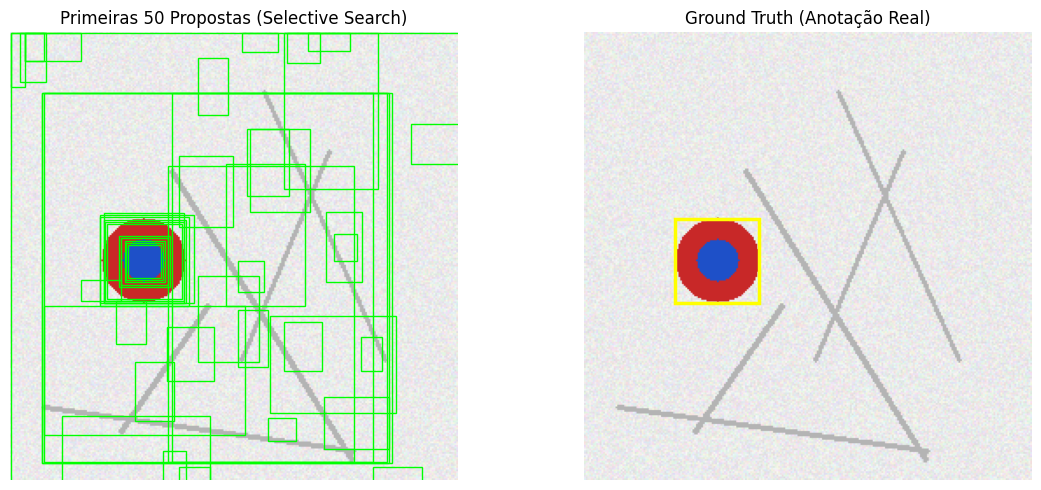

In [4]:
def executar_selective_search(imagem_rgb, modo="fast"):
    """Executa o Selective Search no OpenCV e retorna lista de caixas (x, y, w, h)."""
    ss = cv2.ximgproc.segmentation.createSelectiveSearchSegmentation()
    ss.setBaseImage(cv2.cvtColor(imagem_rgb, cv2.COLOR_RGB2BGR))
    if modo == "fast":
        ss.switchToSelectiveSearchFast()
    else:
        ss.switchToSelectiveSearchQuality()
    rects = ss.process()
    return rects

# Testar na primeira imagem
amostra_path = "dataset_rcnn/images/img_000.png"
img_exemplo = cv2.cvtColor(cv2.imread(amostra_path), cv2.COLOR_BGR2RGB)
rects_exemplo = executar_selective_search(img_exemplo, modo="fast")

print(f"Total de regiões propostas pelo Selective Search: {len(rects_exemplo)}")

# Plotar as 50 primeiras propostas vs. Ground Truth
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].imshow(img_exemplo)
for (x, y, w, h) in rects_exemplo[:50]:
    ax[0].add_patch(patches.Rectangle((x, y), w, h, linewidth=1, edgecolor='lime', facecolor='none'))
ax[0].set_title("Primeiras 50 Propostas (Selective Search)")
ax[0].axis("off")

ax[1].imshow(img_exemplo)
gt_amostra = df_gt[df_gt["filename"] == "img_000.png"]
for _, row in gt_amostra.iterrows():
    ax[1].add_patch(patches.Rectangle((row['x1'], row['y1']), row['x2']-row['x1'], row['y2']-row['y1'],
                                      linewidth=2.5, edgecolor='yellow', facecolor='none'))
ax[1].set_title("Ground Truth (Anotação Real)")
ax[1].axis("off")
plt.tight_layout()
plt.show()

## 3. Preparação dos Dados de Treinamento: Rotulagem via IoU, Balanceamento e *Warping*

Esta etapa resolve três desafios fundamentais da R-CNN:
* **Caso extremo de múltiplos *Ground Truths*:** Se uma proposta se sobrepõe a dois objetos anotados diferentes, atribuímos o rótulo e as coordenadas do objeto *ground truth* com o **maior $\text{IoU}$** (`max_iou`).
* **Balanceamento de classes:** Limitamos o dataset em até **30 positivos** ($\text{IoU} \ge 0.7$, rótulo `1`) e **30 negativos** ($\text{IoU} \le 0.3$, rótulo `0`) por imagem.
* **Entrada espacial fixa (*Warping*):** Cada recorte é redimensionado para **`(224, 224, 3)`**, exigido pela **VGG16**. Também armazenamos os pares `(proposta, ground truth)` das amostras positivas para treinar o regressor de caixas.

In [5]:
imagens_unicas = sorted(df_gt["filename"].unique())
imagens_treino = imagens_unicas[:32]
imagens_teste = imagens_unicas[32:]

X_crops = []
y_labels = []

# Listas para treinar o regressor de bounding box (apenas amostras positivas)
X_reg_crops = []
reg_propostas = []
reg_gts = []

for nome_arq in imagens_treino:
    img_path = os.path.join("dataset_rcnn/images", nome_arq)
    imagem = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
    gt_boxes = df_gt[df_gt["filename"] == nome_arq].to_dict("records")

    rects = executar_selective_search(imagem, modo="fast")[:2000]

    cont_pos, cont_neg = 0, 0
    # Incluir Ground Truths como amostras positivas exatas
    for gt in gt_boxes:
        crop = imagem[gt['y1']:gt['y2'], gt['x1']:gt['x2']]
        if crop.size > 0:
            crop_resized = cv2.resize(crop, (224, 224), interpolation=cv2.INTER_AREA)
            X_crops.append(crop_resized)
            y_labels.append(1)
            cont_pos += 1

    for (x, y, w, h) in rects:
        if cont_pos >= 30 and cont_neg >= 30:
            break
        proposta = {'x1': x, 'y1': y, 'x2': x + w, 'y2': y + h}
        ious = [calcular_iou(proposta, gt) for gt in gt_boxes]
        idx_melhor_gt = int(np.argmax(ious))
        max_iou = ious[idx_melhor_gt]

        if max_iou >= 0.70 and cont_pos < 30:
            crop_resized = cv2.resize(imagem[y:y+h, x:x+w], (224, 224), interpolation=cv2.INTER_AREA)
            X_crops.append(crop_resized)
            y_labels.append(1)
            cont_pos += 1

            # Guardar par (proposta, ground truth) para regressão de coordenadas
            gt_alvo = gt_boxes[idx_melhor_gt]
            X_reg_crops.append(crop_resized)
            reg_propostas.append([x, y, w, h])
            reg_gts.append([gt_alvo['x1'], gt_alvo['y1'], gt_alvo['x2'] - gt_alvo['x1'], gt_alvo['y2'] - gt_alvo['y1']])

        elif max_iou <= 0.30 and cont_neg < 30:
            crop_resized = cv2.resize(imagem[y:y+h, x:x+w], (224, 224), interpolation=cv2.INTER_AREA)
            X_crops.append(crop_resized)
            y_labels.append(0)
            cont_neg += 1

X_dados = preprocess_input(np.array(X_crops, dtype=np.float32))
y_dados = np.array(y_labels, dtype=np.int32)
X_reg_dados = preprocess_input(np.array(X_reg_crops, dtype=np.float32))

print(f"Total de recortes extraídos: {len(X_dados)} | Positivos (1): {np.sum(y_dados==1)} | Negativos (0): {np.sum(y_dados==0)}")
print(f"Amostras positivas pareadas para regressão de BBox: {len(X_reg_dados)}")

X_train, X_val, y_train, y_val = train_test_split(
    X_dados, y_dados, test_size=0.2, random_state=SEED, stratify=y_dados
)

Total de recortes extraídos: 1354 | Positivos (1): 394 | Negativos (0): 960
Amostras positivas pareadas para regressão de BBox: 353


## 4. Construção e Treinamento do Classificador R-CNN (VGG16)

Utilizamos a **VGG16** pré-treinada na ImageNet como extratora de características visuais:
* Congelamos os blocos convolucionais iniciais para preservar detectores genéricos de bordas e texturas, liberando apenas o último bloco convolucional (`block5`) para ajuste fino (*Fine-Tuning*).
* Substituímos a camada de saída original de 1.000 classes por uma cabeça classificadora para distinguir **Objeto (`1`)** vs. **Fundo (`0`)** ($N + 1$ classes).

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool5_flat (Flatten)            │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     6,422,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,137,729 (80.63 MB)

 Trainable params: 13,502,465 (51.51 MB)

 Non-trainable params: 7,635,264 (29.13 MB)

Epoch 1/5
34/34 ━━━━━━━━━━━━━━━━━━━━ 64s 1s/step - accuracy: 0.9677 - loss: 0.2313 - val_accuracy: 1.0000 - val_loss: 1.6539e-06
Epoch 2/5
34/34 ━━━━━━━━━━━━━━━━━━━━ 27s 200ms/step - accuracy: 1.0000 - loss: 4.8147e-05 - val_accuracy: 1.0000 - val_loss: 1.4537e-13
Epoch 3/5
34/34 ━━━━━━━━━━━━━━━━━━━━ 7s 206ms/step - accuracy: 0.9982 - loss: 0.0109 - val_accuracy: 1.0000 - val_loss: 6.0282e-04
Epoch 4/5
34/34 ━━━━━━━━━━━━━━━━━━━━ 7s 205ms/step - accuracy: 0.9982 - loss: 0.0096 - val_accuracy: 1.0000 - val_loss: 1.9820e-16
Epoch 5/5
34/34 ━━━━━━━━━━━━━━━━━━━━ 7s 208ms/step - accuracy: 1.0000 - loss: 5.8130e-14 - val_accuracy: 1.0000 - val_loss: 1.8555e-18


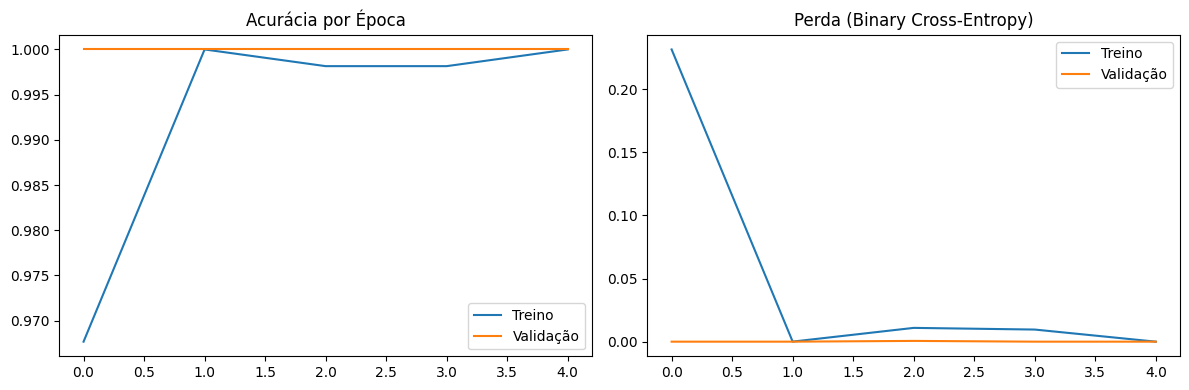

In [6]:
def construir_modelo_rcnn():
    base_vgg = VGG16(weights="imagenet", include_top=False, input_shape=(224, 224, 3))

    # Congelar blocos iniciais e treinar apenas o bloco 5
    for layer in base_vgg.layers[:-4]:
        layer.trainable = False

    x = Flatten(name="pool5_flat")(base_vgg.output)
    x = Dense(256, activation="relu")(x)
    x = Dropout(0.5)(x)
    saida = Dense(1, activation="sigmoid")(x)

    modelo = Model(inputs=base_vgg.input, outputs=saida)
    modelo.compile(
        optimizer=Adam(learning_rate=1e-4),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return modelo

modelo_rcnn = construir_modelo_rcnn()
modelo_rcnn.summary()

historico = modelo_rcnn.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    batch_size=32,
    epochs=5,
    verbose=1
)

# Curvas de aprendizado
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(historico.history['accuracy'], label='Treino')
ax[0].plot(historico.history['val_accuracy'], label='Validação')
ax[0].set_title('Acurácia por Época')
ax[0].legend()

ax[1].plot(historico.history['loss'], label='Treino')
ax[1].plot(historico.history['val_loss'], label='Validação')
ax[1].set_title('Perda (Binary Cross-Entropy)')
ax[1].legend()
plt.tight_layout()
plt.show()

## 5. Regressão da Caixa Delimitadora (*Bounding-Box Regression*)

Conforme proposto na R-CNN original (Girshick et al., 2014), treinamos um **regressor linear Ridge (L2)** sobre os mapas de características extraídos da camada `pool5` (`7 × 7 × 512`) apenas para propostas positivas ($\text{IoU} \ge 0.7$).

O regressor aprende a mapear cada proposta $P = (P_x, P_y, P_w, P_h)$ para o *ground truth* $G = (G_x, G_y, G_w, G_h)$ prevendo quatro deslocamentos normalizados invariantes à escala:

$$t_x = \frac{G_x - P_x}{P_w}, \quad t_y = \frac{G_y - P_y}{P_h}, \quad t_w = \log\left(\frac{G_w}{P_w}\right), \quad t_h = \log\left(\frac{G_h}{P_h}\right)$$

In [7]:
# Extrator de características da camada pool5 (saída convolucional da VGG16)
extrator_pool5 = Model(inputs=modelo_rcnn.input, outputs=modelo_rcnn.get_layer("pool5_flat").output)
features_pool5 = extrator_pool5.predict(X_reg_dados, batch_size=32, verbose=0)

def calcular_alvos_regressao(props, gts):
    """Calcula os deslocamentos normalizados (tx, ty, tw, th) entre proposta P e ground truth G."""
    alvos = []
    for (px, py, pw, ph), (gx, gy, gw, gh) in zip(props, gts):
        pcx, pcy = px + 0.5 * pw, py + 0.5 * ph
        gcx, gcy = gx + 0.5 * gw, gy + 0.5 * gh
        alvos.append([(gcx - pcx) / pw, (gcy - pcy) / ph, np.log(gw / pw), np.log(gh / ph)])
    return np.array(alvos, dtype=np.float32)

def aplicar_regressao_bbox(caixas_yxyx, deltas, img_shape):
    """Aplica os deslocamentos previstos (tx, ty, tw, th) para refinar as coordenadas das caixas."""
    h_img, w_img = img_shape[:2]
    refinadas = []
    for (y1, x1, y2, x2), (tx, ty, tw, th) in zip(caixas_yxyx, deltas):
        pw, ph = x2 - x1, y2 - y1
        pcx, pcy = x1 + 0.5 * pw, y1 + 0.5 * ph

        gcx, gcy = pw * tx + pcx, ph * ty + pcy
        gw, gh = pw * np.exp(tw), ph * np.exp(th)

        nx1 = np.clip(gcx - 0.5 * gw, 0, w_img)
        ny1 = np.clip(gcy - 0.5 * gh, 0, h_img)
        nx2 = np.clip(gcx + 0.5 * gw, 0, w_img)
        ny2 = np.clip(gcy + 0.5 * gh, 0, h_img)
        refinadas.append([ny1, nx1, ny2, nx2])
    return np.array(refinadas, dtype=np.float32)

Y_alvos_reg = calcular_alvos_regressao(reg_propostas, reg_gts)
regressor_bbox = Ridge(alpha=1000.0)
regressor_bbox.fit(features_pool5, Y_alvos_reg)

print(f"Regressor Ridge treinado com {len(Y_alvos_reg)} amostras positivas sobre features pool5 ({features_pool5.shape[1]} dims).")

Regressor Ridge treinado com 353 amostras positivas sobre features pool5 (25088 dims).


## 6. Detecção Final e *Non-Maximum Suppression* (NMS)

Na inferência sobre uma nova imagem:
1. **Filtrar e Refinar:** Descarta propostas com confiança abaixo de `limiar_confianca` (`0.85`) e aplica o **regressor de *bounding box*** sobre as características `pool5` dos recortes aprovados para ajustar suas bordas.
2. **Selecionar Melhor ($M$):** Ordena as caixas refinadas em ordem decrescente de score e elege a caixa $M$ de maior pontuação.
3. **Suprimir Sobreposições:** Compara $M$ com cada caixa restante $B_i$ da mesma classe:
   * Se **$\text{IoU}(M, B_i) > \tau$** (`iou_threshold = 0.30`): alta sobreposição indica detecção redundante do mesmo objeto $\rightarrow$ **suprime $B_i$**.
   * Se **$\text{IoU}(M, B_i) \le \tau$**: baixa sobreposição indica outro objeto distinto $\rightarrow$ **mantém $B_i$**.
4. **Loop:** Repete o processo para a próxima caixa não suprimida até esgotar a lista.

> **Avaliação Pós-NMS (Precisão, Revocação e mAP):** Somente **após o NMS** avalia-se o detector comparando as caixas finais com o *Ground Truth* ($\text{IoU} \ge \tau_{\text{eval}}$). Traça-se a curva $\text{Precisão} = \frac{VP}{VP+FP}$ vs. $\text{Revocação} = \frac{VP}{VP+FN}$ por limiar de confiança; a área sob essa curva define o **AP** de cada classe, e a média entre todas as $N$ classes resulta no **mAP**.

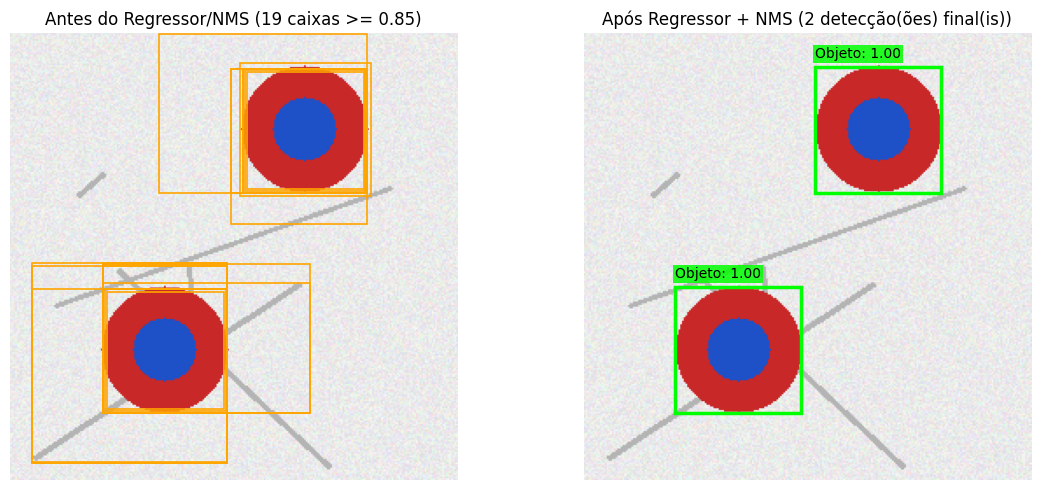

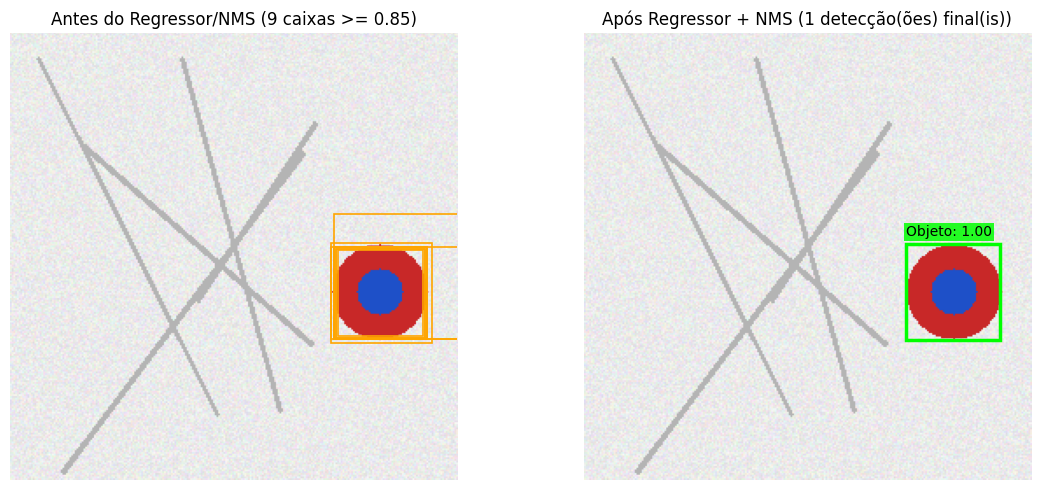

In [8]:
def detectar_objetos_rcnn(img_path, modelo, extrator, regressor, limiar_confianca=0.85, limiar_nms=0.30, max_propostas=400):
    imagem = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
    rects = executar_selective_search(imagem, modo="fast")[:max_propostas]

    crops_lote = []
    caixas_candidatas = []

    for (x, y, w, h) in rects:
        # Ignorar propostas minúsculas ou gigantescas
        if w < 15 or h < 15 or w > 220 or h > 220:
            continue
        crop = cv2.resize(imagem[y:y+h, x:x+w], (224, 224), interpolation=cv2.INTER_AREA)
        crops_lote.append(crop)
        caixas_candidatas.append([y, x, y + h, x + w])  # Formato [y1, x1, y2, x2] para tf.image.non_max_suppression

    lote_tensor = preprocess_input(np.array(crops_lote, dtype=np.float32))
    scores = modelo.predict(lote_tensor, batch_size=32, verbose=0).flatten()

    # Filtrar pelo limiar de confiança
    indices_validos = np.where(scores >= limiar_confianca)[0]
    caixas_filtradas = np.array(caixas_candidatas, dtype=np.float32)[indices_validos]
    scores_filtrados = scores[indices_validos]

    # Refinar coordenadas via Regressor de Bounding Box e aplicar NMS
    if len(caixas_filtradas) > 0:
        feats_validas = extrator.predict(lote_tensor[indices_validos], batch_size=32, verbose=0)
        deltas = regressor.predict(feats_validas)
        caixas_refinadas = aplicar_regressao_bbox(caixas_filtradas, deltas, imagem.shape)

        indices_nms = tf.image.non_max_suppression(
            boxes=caixas_refinadas,
            scores=scores_filtrados,
            max_output_size=10,
            iou_threshold=limiar_nms
        ).numpy()
        caixas_finais = caixas_refinadas[indices_nms]
        scores_finais = scores_filtrados[indices_nms]
    else:
        caixas_finais, scores_finais = [], []

    # Visualizar comparação: Antes do NMS vs. Depois do Regressor + NMS
    fig, ax = plt.subplots(1, 2, figsize=(12, 5))

    ax[0].imshow(imagem)
    for (y1, x1, y2, x2) in caixas_filtradas:
        ax[0].add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, linewidth=1.2, edgecolor='orange', facecolor='none'))
    ax[0].set_title(f"Antes do Regressor/NMS ({len(caixas_filtradas)} caixas >= {limiar_confianca})")
    ax[0].axis("off")

    ax[1].imshow(imagem)
    for (y1, x1, y2, x2), sc in zip(caixas_finais, scores_finais):
        ax[1].add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, linewidth=2.5, edgecolor='lime', facecolor='none'))
        ax[1].text(x1, max(0, y1 - 5), f"Objeto: {sc:.2f}", color='black', fontsize=10,
                   bbox=dict(facecolor='lime', alpha=0.85, edgecolor='none', pad=1.5))
    ax[1].set_title(f"Após Regressor + NMS ({len(caixas_finais)} detecção(ões) final(is))")
    ax[1].axis("off")

    plt.tight_layout()
    plt.show()

# Executar inferência em duas imagens inéditas do conjunto de teste
for img_teste in imagens_teste[:2]:
    detectar_objetos_rcnn(os.path.join("dataset_rcnn/images", img_teste), modelo_rcnn, extrator_pool5, regressor_bbox)

In [9]:
end_time = time.time()

elapsed_time = end_time - start_time
print(f"Training time: {elapsed_time:.2f} seconds")

Training time: 182.31 seconds


## 7. Limitações da R-CNN e Evolução (Fast R-CNN e Faster R-CNN)

1. **Gargalo Computacional na Inferência (~40–50 s/imagem):** Cada proposta de região (até $2.000$ recortes por imagem) passa de forma independente pela CNN, repetindo convoluções sobre pixels sobrepostos.
2. **Treinamento em Múltiplos Estágios Desconectados:** O *Selective Search* é fixo (executado na CPU), a CNN extrai características separadamente e os regressores Ridge (L2) para ajuste fino da caixa $(t_x, t_y, t_w, t_h)$ são treinados em etapas separadas.
3. **Evolução da Família R-CNN:**

| Arquitetura | Propostas de Região | Passagens na CNN | Treinamento | Tempo / Imagem |
| :--- | :--- | :--- | :--- | :--- |
| **R-CNN (2014)** | *Selective Search* (CPU) | ~2.000 por imagem | 3 estágios separados (CNN + SVM + Ridge) | ~40–50 s |
| **Fast R-CNN (2015)** | *Selective Search* + *RoI Pooling* | **1 única passagem** | Unificado (*Multi-task Loss*, 2 cabeças) | ~2 s |
| **Faster R-CNN (2015)** | *Region Proposal Network* (**RPN**) | **1 única passagem** | Ponta a ponta (*end-to-end*) | ~0,2 s (5 FPS) |

# Leitura interessante
Girshick, R., Donahue, J., Darrell, T., & Malik, J. (2014). Rich feature hierarchies for accurate object detection and semantic segmentation (Tech report v5; arXiv:1311.2524). arXiv. https://doi.org/10.48550/arXiv.1311.2524

Uijlings, J. R. R., van de Sande, K. E. A., Gevers, T., & Smeulders, A. W. M. (2013). Selective search for object recognition. International Journal of Computer Vision, 104(2), 154–171. https://doi.org/10.1007/s11263-013-0620-5 ou https://ivi.fnwi.uva.nl/isis/publications/2013/UijlingsIJCV2013/UijlingsIJCV2013.pdf

R-CNN Explained: A Comprehensive Guide to Object Detection Architecture. https://www.aryanupadhyay.com/post/rcnn-object-detection-guide